# Data Processing and Modeling for Fraud Detection

Libreta de procesamiento y modelado de datos para la detección de fraude. Aquí se realizarán las transformaciones necesarias en los datos y se entrenarán modelos para identificar transacciones fraudulentas.

## Librerias necesarias

In [1]:
import pandas as pd
import numpy as np
import os
import time
from itertools import combinations_with_replacement
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

## Cargar los datos preprocesados de México con solo columnas numéricas y la columna is_fraud

In [2]:
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PREPROCESSED_DIR = DATA_DIR / "preprocessed"
mexico_fraud_num = pd.read_csv(PREPROCESSED_DIR / "mexico_fraud_num.csv")
mexico_fraud_num.head()

,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,...,amount_vs_avg_ratio,used_chip,used_pin,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,is_fraud,fraud_amount_lost
0,827.60,8,1,26,188,15400.0,769,1,2,2,...,9.194,0,0,0,90.02,65.89,0,0,0,0.0
1,62.19,9,1,52,2129,14520.0,734,4,1,1,...,0.616,1,0,0,100.98,46.77,0,0,0,0.0
2,71.10,10,0,52,143,4730.0,561,2,1,5,...,0.895,0,0,0,79.40,58.88,0,0,0,0.0
3,13.63,11,0,46,387,4300.0,593,2,0,0,...,0.418,0,0,0,32.58,13.23,2,0,0,0.0
4,103.65,11,0,31,379,10650.0,671,2,0,3,...,0.899,0,0,0,115.25,83.16,0,0,0,0.0


In [3]:
#quitamos la columna fraud_amount_lost por que delata directamente el fraude y no aporta información útil para el modelo
mexico_fraud_num = mexico_fraud_num.drop(columns=["fraud_amount_lost"])


In [4]:
mexico_fraud_num.info()

<class 'pandas.DataFrame'>
RangeIndex: 1921 entries, 0 to 1920
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   transaction_amount           1921 non-null   float64
 1   transaction_hour             1921 non-null   int64  
 2   card_present                 1921 non-null   int64  
 3   customer_age                 1921 non-null   int64  
 4   account_age_days             1921 non-null   int64  
 5   credit_limit                 1921 non-null   float64
 6   credit_score                 1921 non-null   int64  
 7   num_cards_held               1921 non-null   int64  
 8   transactions_last_1h         1921 non-null   int64  
 9   transactions_last_24h        1921 non-null   int64  
 10  transactions_last_7d         1921 non-null   int64  
 11  amount_last_1h               1921 non-null   float64
 12  amount_last_24h              1921 non-null   float64
 13  days_since_last_transaction  

## 3. Separar un 20 % de los datos (renglones) del conjunto para las pruebas finales. Le llamaremos a este conjunto X test y al 80 % restante X train.

In [5]:
## Separar características y etiqueta
X = mexico_fraud_num.drop("is_fraud", axis=1)
y = mexico_fraud_num["is_fraud"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    mexico_fraud_num.drop(columns=["is_fraud"]), 
    mexico_fraud_num["is_fraud"], 
    test_size=0.2, 
    random_state=42
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1536, 26), (385, 26), (1536,), (385,))

## 4. Aplicar PCA a X_train (10 componentes)

Se aplica PCA a las columnas numéricas de `X_train`, conservando las 10 primeras componentes, y la nueva codificación se acompaña de la columna `is_fraud`. Antes de aplicar PCA se estandarizan los datos.

### 4.1 Estandarización

In [7]:
# El scaler se ajusta (fit) solo con X_train: aprende la media y la desviación estándar de cada columna.
# Esos mismos parámetros se reutilizan en el paso 5 para transformar X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_train_scaled.shape

(1536, 26)

### 4.2 PCA con 10 componentes

In [8]:
pca = PCA(n_components=10)
X_train_pca = pca.fit_transform(X_train_scaled)

X_train_pca.shape

(1536, 10)

In [9]:
# Varianza explicada por cada componente y acumulada
pc_cols = [f"PC{i}" for i in range(1, pca.n_components_ + 1)]
varianza_explicada = pd.DataFrame(
    {
        "varianza_explicada": pca.explained_variance_ratio_,
        "varianza_acumulada": pca.explained_variance_ratio_.cumsum(),
    },
    index=pc_cols,
)
varianza_explicada.round(3)

,varianza_explicada,varianza_acumulada
PC1,0.135,0.135
PC2,0.085,0.220
PC3,0.083,0.303
PC4,0.073,0.376
PC5,0.068,0.444
PC6,0.047,0.491
PC7,0.045,0.537
PC8,0.044,0.581
PC9,0.043,0.624
PC10,0.043,0.667


### 4.3 Nueva codificación junto con `is_fraud`

In [10]:
# Nueva codificación de X_train (10 componentes) junto con la etiqueta is_fraud
train_pca = pd.DataFrame(X_train_pca, columns=pc_cols, index=X_train.index)
train_pca["is_fraud"] = y_train
train_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,is_fraud
426,-0.935034,-0.833940,-0.498499,1.002924,-1.477103,1.101725,0.375287,1.446361,-0.825853,-0.439224,0
141,0.308608,-2.071289,1.054005,1.789624,4.975764,-1.052805,-1.337412,0.028955,0.138923,1.246933,0
1157,-1.047522,-0.289483,0.088668,0.502425,-1.065909,1.792025,-0.260425,0.358825,-1.007781,0.050776,0
965,0.695091,-0.289025,-1.552763,-1.292944,0.314069,-1.240280,1.153005,1.380509,0.701538,1.807115,0
1829,-0.090587,-0.977846,-0.297848,-1.716252,0.401468,-0.755966,-1.772982,-0.500341,0.445513,1.293699,0


### 4.4 Comprobación: relación con la SVD

In [11]:
# Comprobación numérica de la relación entre PCA y la SVD de X_train_scaled = U Σ Vᵀ
# (X_train_scaled ya está centrada por el StandardScaler, así que no hay que restar la media)
U, S, Vt = np.linalg.svd(X_train_scaled, full_matrices=False)
n = X_train_scaled.shape[0]

# Los signos de los vectores singulares son arbitrarios, por eso se comparan valores absolutos
print("components_ == primeras 10 filas de Vᵀ:", np.allclose(np.abs(pca.components_), np.abs(Vt[:10])))
print("X_train_pca == U₁₀ Σ₁₀:              ", np.allclose(np.abs(X_train_pca), np.abs(U[:, :10] * S[:10])))
print("varianzas == σᵢ² / (n − 1):           ", np.allclose(pca.explained_variance_, S[:10] ** 2 / (n - 1)))

components_ == primeras 10 filas de Vᵀ: True
X_train_pca == U₁₀ Σ₁₀:               True
varianzas == σᵢ² / (n − 1):            True


## 5. Preparar el conjunto de prueba: X_test_pca

A `X_test` se le aplican `scaler.transform` y después `pca.transform`. No se hace de cero la reducción de dimensionalidad: se reutilizan el escalado y las 10 componentes **aprendidas en X_train**.

### 5.1 Aplicar el scaler y el PCA aprendidos en X_train

In [12]:
# Solo transform (NO fit_transform): se usan la media, la desviación estándar y las
# componentes aprendidas en X_train. No se vuelve a calcular nada a partir de X_test.
X_test_scaled = scaler.transform(X_test)
X_test_pca = pca.transform(X_test_scaled)

X_test_pca.shape

(385, 10)

In [13]:
# Conjunto de prueba en la nueva codificación, junto con la etiqueta is_fraud
test_pca = pd.DataFrame(X_test_pca, columns=pc_cols, index=X_test.index)
test_pca["is_fraud"] = y_test

print(test_pca["is_fraud"].value_counts())
test_pca.head()

is_fraud
0    377
1      8
Name: count, dtype: int64


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,is_fraud
998,-1.456016,1.692196,-0.688673,1.859258,1.280100,-1.147007,0.315056,-1.263813,-0.795691,0.673406,0
1622,0.222359,-0.829764,-0.179732,-2.300358,1.157286,0.579957,0.093681,1.542099,-1.104826,-0.302438,0
611,-0.544944,-0.474413,1.023892,-0.355315,0.260815,0.818989,-1.305393,1.663282,-0.987589,0.163778,0
514,-1.128417,-0.861273,-1.055243,-1.100048,0.238879,0.817473,0.989197,-0.993108,1.343981,-1.204149,0
413,-0.861560,0.030350,-0.949735,0.283192,0.670376,0.759426,-0.592071,0.368862,0.027957,0.388709,0


### 5.2 Comprobación: ¿qué se calcula exactamente?

Cada transacción de prueba se estandariza con la media y desviación de `X_train` y luego se proyecta sobre las 10 direcciones principales de `X_train` (las columnas de $V_{10}$):

$$X_{\text{test\_pca}} = \left(\frac{X_{\text{test}} - \mu_{\text{train}}}{\sigma_{\text{train}}}\right) V_{10}$$

In [14]:
# Cálculo "a mano": X_test_pca = ((X_test − μ_train) / σ_train) · V₁₀
mu_train = scaler.mean_       # media de cada columna en X_train (26 valores)
sigma_train = scaler.scale_   # desviación estándar de cada columna en X_train (26 valores)
V10 = pca.components_.T       # matriz 26 × 10: las 10 direcciones principales de X_train

X_test_pca_manual = ((X_test.to_numpy() - mu_train) / sigma_train) @ V10

print("¿Coincide con scaler.transform + pca.transform?", np.allclose(X_test_pca, X_test_pca_manual))

¿Coincide con scaler.transform + pca.transform? True


## Parte 2. Primera propuesta: distancia de Mahalanobis

Se toman las transacciones legítimas de `X_train_pca` (`X_train_legit`) y su matriz de covarianzas Σ. La distancia de Mahalanobis al origen es

$$d_M(x)^2 = x^T \Sigma^{-1} x$$

Para cada porcentaje entero n % se busca un radio ρₙ tal que la bola $B_{\rho_n}(0) = \{x : d_M(x) \le \rho_n\}$ contenga el n % de las transacciones legítimas, pero no el (n+1) %.

### 2.1 Distancia de Mahalanobis y radio ρₙ

In [15]:
def distancia_mahalanobis(X, sigma_inv):
    """d_M(x) = √(xᵀ Σ⁻¹ x) para cada renglón x de X (distancia al origen)."""
    return np.sqrt(np.sum((X @ sigma_inv) * X, axis=1))


def radio(distancias, n):
    """Radio ρₙ tal que la bola B_ρₙ(0) contiene el n % de los datos, pero no el (n+1) %.

    Se ordenan las distancias y se toma la k-ésima más pequeña, con k = ⌈n·N/100⌉
    (el mínimo número de puntos que cubre el n %).
    """
    assert 1 <= n <= 100, "n debe ser un porcentaje entero entre 1 y 100"
    d = np.sort(distancias)
    k = int(np.ceil(n * len(d) / 100))
    return d[k - 1]

### 2.2 Transacciones legítimas y fraudulentas de entrenamiento

In [16]:
# Separar las transacciones de entrenamiento (ya en la codificación PCA) según su etiqueta
es_legit = (y_train == 0).to_numpy()
X_train_legit = X_train_pca[es_legit]
X_train_fraude = X_train_pca[~es_legit]

print("X_train_legit: ", X_train_legit.shape)
print("X_train_fraude:", X_train_fraude.shape)

X_train_legit:  (1492, 10)
X_train_fraude: (44, 10)


### 2.3 Método completo para k componentes

Con las primeras k componentes:

1. **Σ** = matriz de covarianzas de `X_train_legit`.
2. **Radios ρ₅₀, ρ₇₅, ρ₉₀, ρ₉₅, ρ₉₉** a partir de las distancias de las transacciones legítimas.
3. **Zonas de seguridad** a partir de las distancias de los **fraudes** de entrenamiento. Sea r_c el radio de la bola que contiene el c % de los fraudes (la misma función `radio`, aplicada a los fraudes):

| Zona | Distancia | Interpretación |
|---|---|---|
| Seguridad extrema | d ≤ r₁₀ | a lo más el 10 % de los fraudes está así de cerca |
| Seguridad alta | r₁₀ < d ≤ r₂₅ | aquí cae entre el 10 % y el 25 % de los fraudes |
| Seguridad baja | r₂₅ < d ≤ r₅₀ | aquí cae entre el 25 % y el 50 % de los fraudes |
| Peligro | d > r₅₀ | aquí está la mitad más lejana de los fraudes |

   Los cortes 10 / 25 / 50 son una decisión de diseño y se pueden cambiar en `CORTES_FRAUDE`.

4. **Validación** con `X_test_pca`: una transacción se marca como **fraude si queda fuera de la bola** (d > ρ) y se cuentan falsos positivos (legítimas marcadas como fraude) y falsos negativos (fraudes no detectados).

In [17]:
PORCENTAJES = [50, 75, 90, 95, 99]   # % de transacciones legítimas dentro de cada bola
CORTES_FRAUDE = [10, 25, 50]         # % de fraudes de entrenamiento que definen las zonas (decisión de diseño)
ZONAS = ["Seguridad extrema", "Seguridad alta", "Seguridad baja", "Peligro"]


def mahalanobis(k):
    """Ajusta el método con las primeras k componentes y calcula las distancias de X_test_pca."""
    inicio = time.perf_counter()

    legit, fraude, test = X_train_legit[:, :k], X_train_fraude[:, :k], X_test_pca[:, :k]
    sigma = np.cov(legit, rowvar=False)  # Σ de las transacciones legítimas (k × k)
    sigma_inv = np.linalg.inv(sigma)
    d_legit = distancia_mahalanobis(legit, sigma_inv)
    d_fraude = distancia_mahalanobis(fraude, sigma_inv)

    modelo = {
        "k": k,
        "sigma": sigma,
        "d_legit": d_legit,
        "d_fraude": d_fraude,
        "radios": {n: radio(d_legit, n) for n in PORCENTAJES},
        "radios_zona": [radio(d_fraude, c) for c in CORTES_FRAUDE],
        "d_test": distancia_mahalanobis(test, sigma_inv),
    }
    modelo["tiempo_s"] = time.perf_counter() - inicio
    return modelo

In [18]:
def tabla_radios(modelo):
    """% de legítimas y de fraudes de entrenamiento dentro de cada bola B_ρₙ(0)."""
    radios = modelo["radios"]
    return pd.DataFrame(
        {
            "ρ": radios.values(),
            "% legítimas dentro": [100 * np.mean(modelo["d_legit"] <= r) for r in radios.values()],
            "% fraudes dentro": [100 * np.mean(modelo["d_fraude"] <= r) for r in radios.values()],
        },
        index=[f"ρ{n}" for n in radios],
    ).round(2)


def tabla_zonas(modelo):
    """Transacciones legítimas y fraudulentas de X_test_pca en cada zona de seguridad."""
    zona = np.searchsorted(modelo["radios_zona"], modelo["d_test"])  # 0 = extrema, …, 3 = peligro
    y_real = y_test.to_numpy()
    tabla = pd.DataFrame(
        {
            "radio exterior": [*modelo["radios_zona"], np.inf],
            "legítimas": [np.sum((zona == i) & (y_real == 0)) for i in range(len(ZONAS))],
            "fraudes": [np.sum((zona == i) & (y_real == 1)) for i in range(len(ZONAS))],
        },
        index=ZONAS,
    )
    tabla["% fraude en la zona"] = 100 * tabla["fraudes"] / (tabla["legítimas"] + tabla["fraudes"])
    return tabla.round(2)


def tabla_confusion(modelo):
    """Matriz de confusión en un renglón para cada umbral (fraude si d > ρ), evaluada en X_test_pca."""
    umbrales = {f"ρ{n}": r for n, r in modelo["radios"].items()}
    umbrales["inicio zona Peligro"] = modelo["radios_zona"][-1]
    filas = []
    for nombre, r in umbrales.items():
        prediccion = (modelo["d_test"] > r).astype(int)
        vn, fp, fn, vp = confusion_matrix(y_test, prediccion, labels=[0, 1]).ravel()
        filas.append({"umbral": nombre, "ρ": r, "VN": vn, "FP": fp, "FN": fn, "VP": vp})
    return pd.DataFrame(filas).set_index("umbral").round(2)

### 2.4 Ejercicio didáctico con 2 componentes

Con solo PC1 y PC2 las bolas de Mahalanobis son elipses y se pueden graficar.

In [19]:
m2 = mahalanobis(2)

# Comprobación del programa para todos los porcentajes enteros: B_ρₙ(0) contiene el n %, pero no el (n+1) %
pct_dentro = {n: 100 * np.mean(m2["d_legit"] <= radio(m2["d_legit"], n)) for n in range(1, 100)}
assert all(n <= p < n + 1 for n, p in pct_dentro.items())
print("✓ Para n = 1, …, 99 la bola B_ρₙ(0) contiene el n % de las legítimas, pero no el (n+1) %")

tabla_radios(m2)

✓ Para n = 1, …, 99 la bola B_ρₙ(0) contiene el n % de las legítimas, pero no el (n+1) %


,ρ,% legítimas dentro,% fraudes dentro
ρ50,1.07,50.00,38.64
ρ75,1.38,75.00,75.00
ρ90,1.91,90.01,93.18
ρ95,2.36,95.04,100.00
ρ99,4.06,99.06,100.00


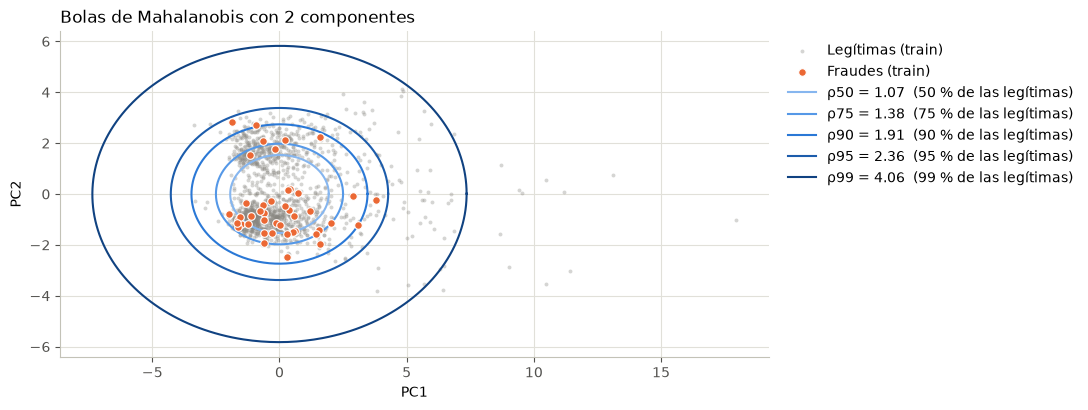

In [20]:
def elipse(radio, sigma, puntos=400):
    """Frontera de la bola {x ∈ R² : xᵀ Σ⁻¹ x = ρ²}.

    Si Σ = L Lᵀ (Cholesky) y u recorre el círculo unitario, entonces x = ρ L u cumple xᵀ Σ⁻¹ x = ρ².
    """
    L = np.linalg.cholesky(sigma)
    t = np.linspace(0, 2 * np.pi, puntos)
    circulo = np.vstack([np.cos(t), np.sin(t)])
    return (radio * L @ circulo).T


COLOR_LEGIT = "#898781"   # gris: contexto
COLOR_FRAUDE = "#eb6834"  # naranja: fraudes
COLORES_RADIOS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]  # azul, de claro (ρ50) a oscuro (ρ99)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(*X_train_legit[:, :2].T, s=8, color=COLOR_LEGIT, alpha=0.35, linewidths=0, label="Legítimas (train)")
ax.scatter(*X_train_fraude[:, :2].T, s=30, color=COLOR_FRAUDE, edgecolors="white", linewidths=0.8,
           zorder=3, label="Fraudes (train)")
for (n, r), color in zip(m2["radios"].items(), COLORES_RADIOS):
    ex, ey = elipse(r, m2["sigma"]).T
    ax.plot(ex, ey, color=color, linewidth=1.5, label=f"ρ{n} = {r:.2f}  ({n} % de las legítimas)")

ax.set_title("Bolas de Mahalanobis con 2 componentes", loc="left")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_aspect("equal", adjustable="box")  # misma escala en ambos ejes: las elipses se ven con su forma real
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [21]:
# Zonas de seguridad y validación en X_test_pca (2 componentes)
display(tabla_zonas(m2))
tabla_confusion(m2)

,radio exterior,legítimas,fraudes,% fraude en la zona
Seguridad extrema,0.41,25,0,0.00
Seguridad alta,0.76,75,2,2.60
Seguridad baja,1.11,109,2,1.80
Peligro,inf,168,4,2.33


,ρ,VN,FP,FN,VP
umbral,,,,,
ρ50,1.07,199,178,4,4
ρ75,1.38,269,108,6,2
ρ90,1.91,349,28,8,0
ρ95,2.36,363,14,8,0
ρ99,4.06,375,2,8,0
inicio zona Peligro,1.11,209,168,4,4


### 2.5 Con las 10 componentes

Mismo método, ahora con las 10 componentes de `X_train_pca`. Las bolas ya no se pueden graficar, pero los radios, las zonas y la validación se calculan igual.

In [22]:
m10 = mahalanobis(10)
tabla_radios(m10)

,ρ,% legítimas dentro,% fraudes dentro
ρ50,2.72,50.00,43.18
ρ75,3.38,75.00,70.45
ρ90,4.18,90.01,95.45
ρ95,4.79,95.04,97.73
ρ99,7.06,99.06,100.00


In [23]:
# Zonas de seguridad y validación en X_test_pca (10 componentes)
display(tabla_zonas(m10))
tabla_confusion(m10)

,radio exterior,legítimas,fraudes,% fraude en la zona
Seguridad extrema,1.91,28,0,0.00
Seguridad alta,2.35,63,2,3.08
Seguridad baja,2.94,133,4,2.92
Peligro,inf,153,2,1.29


,ρ,VN,FP,FN,VP
umbral,,,,,
ρ50,2.72,178,199,4,4
ρ75,3.38,288,89,6,2
ρ90,4.18,340,37,6,2
ρ95,4.79,358,19,7,1
ρ99,7.06,373,4,8,0
inicio zona Peligro,2.94,224,153,6,2


### 2.6 Comparación: 2 vs 10 componentes

In [24]:
# Resumen para el reporte: varianza explicada, tiempo de ejecución y matriz de confusión en un renglón
resumen = []
for modelo in [m2, m10]:
    confusion = tabla_confusion(modelo)
    for umbral in ["ρ95", "inicio zona Peligro"]:
        vn, fp, fn, vp = (int(confusion.loc[umbral, c]) for c in ["VN", "FP", "FN", "VP"])
        resumen.append({
            "componentes": modelo["k"],
            "umbral": umbral,
            "varianza explicada": pca.explained_variance_ratio_[: modelo["k"]].sum(),
            "tiempo (ms)": 1000 * modelo["tiempo_s"],
            "VN": vn, "FP": fp, "FN": fn, "VP": vp,
            "% fraudes detectados": 100 * vp / (vp + fn),
            "% falsas alarmas": 100 * fp / (fp + vn),
        })

pd.DataFrame(resumen).set_index(["componentes", "umbral"]).round(3)

varianza explicada  tiempo (ms)   VN   FP  \
componentes umbral                                                           
2           ρ95                               0.220        5.326  363   14   
            inicio zona Peligro               0.220        5.326  209  168   
10          ρ95                               0.667        0.881  358   19   
            inicio zona Peligro               0.667        0.881  224  153   

                                 FN  VP  % fraudes detectados  \
componentes umbral                                              
2           ρ95                   8   0                   0.0   
            inicio zona Peligro   4   4                  50.0   
10          ρ95                   7   1                  12.5   
            inicio zona Peligro   6   2                  25.0   

                                 % falsas alarmas  
componentes umbral                                 
2           ρ95                             3.714  
            inicio zona Peligro            44.562  
10          ρ95                             5.040  
            inicio zona Peligro            40.584

## Parte 3. Segunda propuesta: kernel de Christoffel-Darboux

Cada transacción legítima x (primeras k componentes de `X_train_legit`) se recodifica con Φ(x): todos los monomios de grado ≤ d. Con 2 componentes y grado 2:

$$\Phi(x) = (1,\ x_1,\ x_2,\ x_1^2,\ x_1x_2,\ x_2^2)$$

- **Matriz de momentos empírica:** $M_n = \frac{1}{N} D^T D$, donde los renglones de $D$ son $\Phi(x)$.
- **Regularización de Tikhonov:** $M_{reg} = M_n + \epsilon I$, con $\epsilon = 10^{-6}$.
- **Polinomio de Christoffel-Darboux:** $p_{CD}(x) = \Phi(x)^T M_{reg}^{-1} \Phi(x)$.
- **Subconjuntos de nivel:** $S_\rho = \{x : p_{CD}(x) \le \rho\}$.

Valores pequeños de $p_{CD}$ indican que x se parece a las transacciones legítimas y valores grandes, que está lejos de ellas. Los radios ρₙ, las zonas de seguridad y la validación se calculan igual que en la Parte 2, cambiando $d_M$ por $p_{CD}$.

### 3.1 Base de monomios y polinomio de Christoffel-Darboux

In [25]:
EPSILON = 1e-6  # regularización de Tikhonov (ridge)


def exponentes(k, grado):
    """Exponentes (a₁, …, a_k) de todos los monomios x₁^a₁ ⋯ x_k^a_k de grado total ≤ grado.

    Cada renglón es un monomio, ordenados por grado: 1, x₁, x₂, x₁², x₁x₂, x₂², …
    """
    lista = []
    for g in range(grado + 1):
        for indices in combinations_with_replacement(range(k), g):
            lista.append(np.bincount(np.array(indices, dtype=int), minlength=k))
    return np.array(lista)


def nombres_monomios(E):
    """Nombres legibles de los monomios, p. ej. 'x1²·x2'."""
    superindice = str.maketrans("0123456789", "⁰¹²³⁴⁵⁶⁷⁸⁹")
    nombres = []
    for fila in E:
        partes = [f"x{i + 1}" + (str(a).translate(superindice) if a > 1 else "") for i, a in enumerate(fila) if a > 0]
        nombres.append("·".join(partes) or "1")
    return nombres


def phi(X, E):
    """Codificación Φ(x): evalúa cada monomio (columna) en cada transacción (renglón)."""
    return np.column_stack([np.prod(X ** e, axis=1) for e in E])


def ajustar_cd(X_legit, grado, epsilon=EPSILON):
    """Base de monomios E y matriz de momentos regularizada M_reg = (1/N) DᵀD + εI."""
    E = exponentes(X_legit.shape[1], grado)
    D = phi(X_legit, E)                       # N × (número de monomios)
    M = D.T @ D / len(D)                      # matriz de momentos empírica
    return E, M + epsilon * np.eye(len(E))    # regularización de Tikhonov


def p_cd(X, E, M_reg):
    """Polinomio de Christoffel-Darboux p_CD(x) = Φ(x)ᵀ M_reg⁻¹ Φ(x) para cada renglón x de X.

    Se usa solve en lugar de calcular M_reg⁻¹ explícitamente: da el mismo resultado y es más estable.
    """
    F = phi(X, E)
    return np.sum(F * np.linalg.solve(M_reg, F.T).T, axis=1)

In [26]:
def christoffel_darboux(k, grado):
    """Ajusta el kernel CD con las primeras k componentes y una base de grado `grado`.

    Los valores de p_CD se guardan con las mismas llaves que en `mahalanobis` ("d_legit", "d_fraude",
    "d_test") para reutilizar tabla_radios, tabla_zonas y tabla_confusion de la Parte 2.
    """
    inicio = time.perf_counter()

    legit, fraude, test = X_train_legit[:, :k], X_train_fraude[:, :k], X_test_pca[:, :k]
    E, M_reg = ajustar_cd(legit, grado)
    p_legit = p_cd(legit, E, M_reg)
    p_fraude = p_cd(fraude, E, M_reg)

    modelo = {
        "k": k,
        "grado": grado,
        "E": E,
        "M_reg": M_reg,
        "d_legit": p_legit,
        "d_fraude": p_fraude,
        "radios": {n: radio(p_legit, n) for n in PORCENTAJES},
        "radios_zona": [radio(p_fraude, c) for c in CORTES_FRAUDE],
        "d_test": p_cd(test, E, M_reg),
    }
    modelo["tiempo_s"] = time.perf_counter() - inicio
    return modelo

### 3.2 Bases de polinomios con 2 componentes

In [27]:
for grado in [2, 4]:
    E_grado = exponentes(2, grado)
    print(f"Grado {grado} ({len(E_grado)} monomios): " + ", ".join(nombres_monomios(E_grado)))

Grado 2 (6 monomios): 1, x1, x2, x1², x1·x2, x2²
Grado 4 (15 monomios): 1, x1, x2, x1², x1·x2, x2², x1³, x1²·x2, x1·x2², x2³, x1⁴, x1³·x2, x1²·x2², x1·x2³, x2⁴


### 3.3 Comprobación: relación con la distancia de Mahalanobis

In [28]:
# Con la base de grado 1, Φ(x) = (1, x₁, x₂), el polinomio de CD coincide con 1 + la distancia de
# Mahalanobis² medida desde la media μ de las legítimas (con la covarianza que divide entre N)
legit_2d = X_train_legit[:, :2]
E1, M1 = ajustar_cd(legit_2d, grado=1, epsilon=0)
mu = legit_2d.mean(axis=0)
sigma_N = np.cov(legit_2d, rowvar=False, bias=True)
dif = legit_2d - mu
d2_desde_media = np.sum((dif @ np.linalg.inv(sigma_N)) * dif, axis=1)

print("p_CD(x) == 1 + (x − μ)ᵀ Σ⁻¹ (x − μ):", np.allclose(p_cd(legit_2d, E1, M1), 1 + d2_desde_media))

p_CD(x) == 1 + (x − μ)ᵀ Σ⁻¹ (x − μ): True


### 3.4 Ejercicio con 2 componentes: grado 2 y grado 4

Se repite el ejercicio de la Parte 2, ahora con los subconjuntos de nivel $S_{\rho_n}$ para ρ₅₀, ρ₇₅, ρ₉₀, ρ₉₅ y ρ₉₉.

In [29]:
modelos_cd = {(2, grado): christoffel_darboux(2, grado) for grado in [2, 4]}

# % de legítimas y de fraudes de entrenamiento dentro de cada subconjunto de nivel S_ρₙ
pd.concat({f"grado {g}": tabla_radios(modelos_cd[(2, g)]) for g in [2, 4]}, axis=1)

grado 2                                     grado 4                     \
          ρ % legítimas dentro % fraudes dentro       ρ % legítimas dentro   
ρ50    3.06              50.00            36.36    5.50              50.00   
ρ75    4.67              75.00            75.00    9.13              75.00   
ρ90    8.41              90.01            90.91   19.69              90.01   
ρ95   12.78              95.04            95.45   36.11              95.04   
ρ99   69.01              99.06           100.00  222.47              99.06   

                      
    % fraudes dentro  
ρ50            43.18  
ρ75            70.45  
ρ90            90.91  
ρ95            95.45  
ρ99           100.00

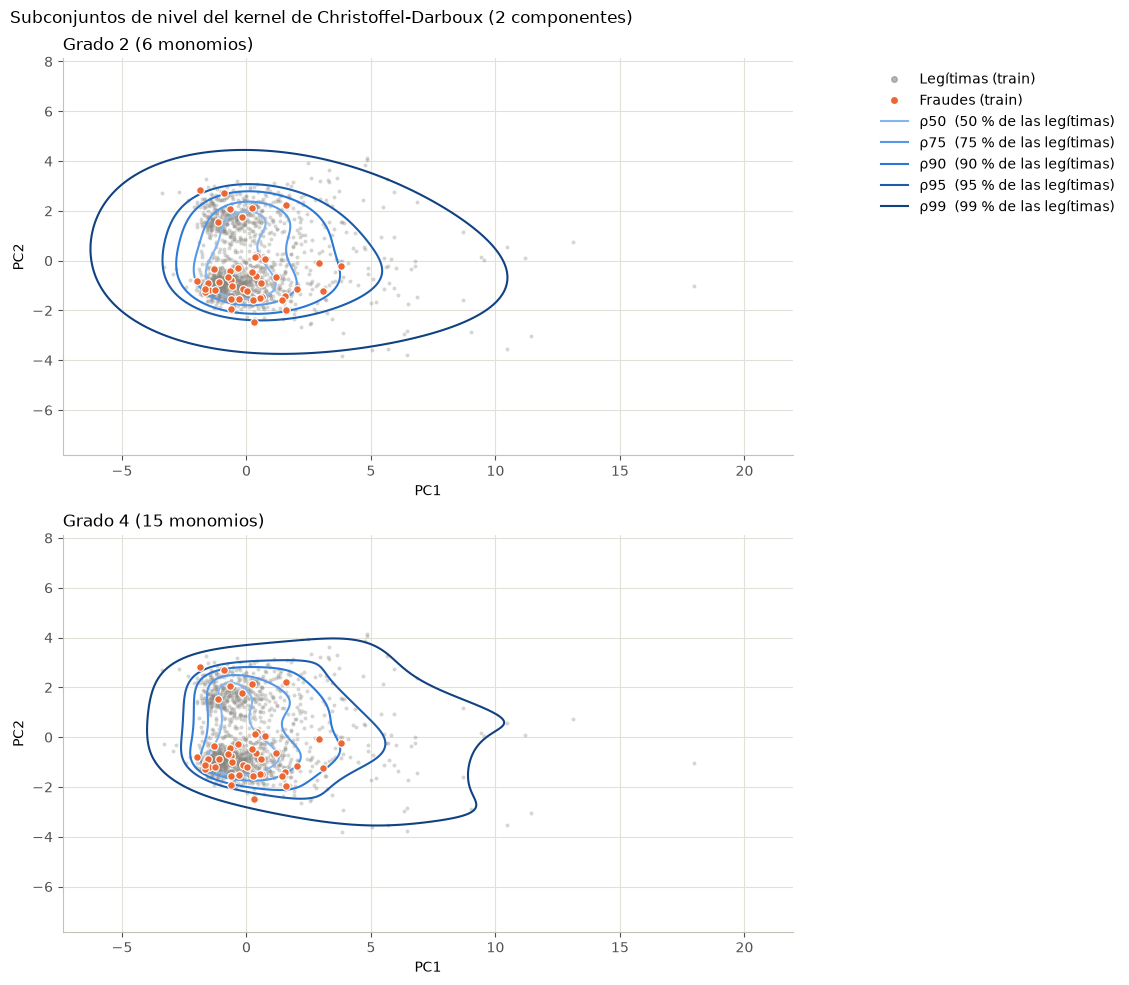

In [30]:
def graficar_curvas_nivel(ax, modelo, margen=4):
    """Curvas de nivel {x : p_CD(x) = ρₙ} junto con las transacciones de entrenamiento (2 componentes)."""
    puntos = np.vstack([X_train_legit[:, :2], X_train_fraude[:, :2]])
    (x_min, y_min), (x_max, y_max) = puntos.min(axis=0) - margen, puntos.max(axis=0) + margen
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
    zz = p_cd(np.column_stack([xx.ravel(), yy.ravel()]), modelo["E"], modelo["M_reg"]).reshape(xx.shape)

    ax.scatter(*X_train_legit[:, :2].T, s=8, color=COLOR_LEGIT, alpha=0.35, linewidths=0)
    ax.scatter(*X_train_fraude[:, :2].T, s=30, color=COLOR_FRAUDE, edgecolors="white", linewidths=0.8, zorder=3)
    ax.contour(xx, yy, zz, levels=list(modelo["radios"].values()), colors=COLORES_RADIOS, linewidths=1.5)

    ax.set_title(f"Grado {modelo['grado']} ({len(modelo['E'])} monomios)", loc="left")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e")


fig, axes = plt.subplots(2, 1, figsize=(11, 10))
for ax, grado in zip(axes, [2, 4]):
    graficar_curvas_nivel(ax, modelos_cd[(2, grado)])

leyenda = [
    Line2D([], [], marker="o", linestyle="", markersize=4, color=COLOR_LEGIT, alpha=0.6, label="Legítimas (train)"),
    Line2D([], [], marker="o", linestyle="", markersize=6, color=COLOR_FRAUDE, markeredgecolor="white",
           label="Fraudes (train)"),
    *[Line2D([], [], color=c, linewidth=1.5, label=f"ρ{n}  ({n} % de las legítimas)")
      for n, c in zip(PORCENTAJES, COLORES_RADIOS)],
]
fig.legend(handles=leyenda, frameon=False, loc="upper left", bbox_to_anchor=(0.80, 0.93))
fig.suptitle("Subconjuntos de nivel del kernel de Christoffel-Darboux (2 componentes)", x=0.02, ha="left")
plt.tight_layout(rect=(0, 0, 0.80, 1))
plt.show()

In [31]:
# Zonas de seguridad y validación en X_test_pca (2 componentes)
for grado in [2, 4]:
    modelo = modelos_cd[(2, grado)]
    print(f"\n=== Kernel CD · 2 componentes · grado {grado} ===")
    display(tabla_zonas(modelo))
    display(tabla_confusion(modelo))


=== Kernel CD · 2 componentes · grado 2 ===


,radio exterior,legítimas,fraudes,% fraude en la zona
Seguridad extrema,1.77,46,1,2.13
Seguridad alta,2.16,44,1,2.22
Seguridad baja,3.22,109,2,1.80
Peligro,inf,178,4,2.20


,ρ,VN,FP,FN,VP
umbral,,,,,
ρ50,3.06,184,193,4,4
ρ75,4.67,276,101,6,2
ρ90,8.41,345,32,8,0
ρ95,12.78,366,11,8,0
ρ99,69.01,375,2,8,0
inicio zona Peligro,3.22,199,178,4,4



=== Kernel CD · 2 componentes · grado 4 ===


,radio exterior,legítimas,fraudes,% fraude en la zona
Seguridad extrema,3.09,59,2,3.28
Seguridad alta,3.85,42,1,2.33
Seguridad baja,6.02,115,1,0.86
Peligro,inf,161,4,2.42


,ρ,VN,FP,FN,VP
umbral,,,,,
ρ50,5.50,193,184,4,4
ρ75,9.13,284,93,8,0
ρ90,19.69,342,35,8,0
ρ95,36.11,365,12,8,0
ρ99,222.47,375,2,8,0
inicio zona Peligro,6.02,216,161,4,4


### 3.5 Con 5, 7 y 10 componentes

Mismo método con bases de grado 2 y 4. El número de monomios de grado ≤ d en k variables es $\binom{k+d}{d}$, así que la matriz de momentos crece muy rápido: con 10 componentes y grado 4 es de 1001 × 1001.

In [32]:
for k in [5, 7, 10]:
    for grado in [2, 4]:
        modelos_cd[(k, grado)] = christoffel_darboux(k, grado)

# Tamaño de la base, tiempo y una señal de sobreajuste: qué % de las legítimas de PRUEBA queda dentro de ρ95
# (si el modelo generaliza bien debería ser cercano a 95 %)
y_test_legit = y_test.to_numpy() == 0
pd.DataFrame(
    [
        {
            "componentes": k,
            "grado": grado,
            "monomios": len(m["E"]),
            "tiempo (ms)": 1000 * m["tiempo_s"],
            "% legítimas de test dentro de ρ95": 100 * np.mean(m["d_test"][y_test_legit] <= m["radios"][95]),
        }
        for (k, grado), m in modelos_cd.items()
    ]
).set_index(["componentes", "grado"]).round(2)

monomios  tiempo (ms)  % legítimas de test dentro de ρ95
componentes grado                                                          
2           2             6         1.51                              97.08
            4            15         1.94                              96.82
5           2            21         9.92                              97.08
            4           126        82.33                              94.96
7           2            36        25.08                              96.82
            4           330        79.73                              84.35
10          2            66        15.38                              94.69
            4          1001       303.87                              25.20

### 3.6 Comparación final: Mahalanobis vs kernel CD

Resumen para el reporte con `X_test_pca`: varianza explicada, tiempo de ejecución y matriz de confusión en un renglón. El umbral es ρ₉₅ (una transacción es fraude si queda fuera de la bola / del subconjunto de nivel que contiene el 95 % de las legítimas) y se puede cambiar en `UMBRAL_REPORTE`.

In [33]:
UMBRAL_REPORTE = "ρ95"  # umbral para la matriz de confusión del reporte (se puede cambiar, p. ej. "ρ90")


def fila_resumen(metodo, modelo, base):
    """Un renglón del reporte: varianza explicada, tiempo y matriz de confusión en X_test_pca."""
    confusion = tabla_confusion(modelo)
    vn, fp, fn, vp = (int(confusion.loc[UMBRAL_REPORTE, c]) for c in ["VN", "FP", "FN", "VP"])
    return {
        "método": metodo,
        "componentes": modelo["k"],
        "base": base,
        "varianza explicada": pca.explained_variance_ratio_[: modelo["k"]].sum(),
        "tiempo (ms)": 1000 * modelo["tiempo_s"],
        "VN": vn, "FP": fp, "FN": fn, "VP": vp,
        "% fraudes detectados": 100 * vp / (vp + fn),
        "% falsas alarmas": 100 * fp / (fp + vn),
    }


filas = [fila_resumen("Mahalanobis", m, "—") for m in [m2, m10]]
filas += [fila_resumen("Kernel CD", m, f"grado {m['grado']} ({len(m['E'])} monomios)") for m in modelos_cd.values()]

pd.DataFrame(filas).set_index(["método", "componentes", "base"]).round(2)

varianza explicada  \
método      componentes base                                          
Mahalanobis 2           —                                      0.22   
            10          —                                      0.67   
Kernel CD   2           grado 2 (6 monomios)                   0.22   
                        grado 4 (15 monomios)                  0.22   
            5           grado 2 (21 monomios)                  0.44   
                        grado 4 (126 monomios)                 0.44   
            7           grado 2 (36 monomios)                  0.54   
                        grado 4 (330 monomios)                 0.54   
            10          grado 2 (66 monomios)                  0.67   
                        grado 4 (1001 monomios)                0.67   

                                                 tiempo (ms)   VN   FP  FN  \
método      componentes base                                                 
Mahalanobis 2           —                               5.33  363   14   8   
            10          —                               0.88  358   19   7   
Kernel CD   2           grado 2 (6 monomios)            1.51  366   11   8   
                        grado 4 (15 monomios)           1.94  365   12   8   
            5           grado 2 (21 monomios)           9.92  366   11   8   
                        grado 4 (126 monomios)         82.33  358   19   8   
            7           grado 2 (36 monomios)          25.08  365   12   7   
                        grado 4 (330 monomios)         79.73  318   59   7   
            10          grado 2 (66 monomios)          15.38  357   20   7   
                        grado 4 (1001 monomios)       303.87   95  282   2   

                                                 VP  % fraudes detectados  \
método      componentes base                                                
Mahalanobis 2           —                         0                   0.0   
            10          —                         1                  12.5   
Kernel CD   2           grado 2 (6 monomios)      0                   0.0   
                        grado 4 (15 monomios)     0                   0.0   
            5           grado 2 (21 monomios)     0                   0.0   
                        grado 4 (126 monomios)    0                   0.0   
            7           grado 2 (36 monomios)     1                  12.5   
                        grado 4 (330 monomios)    1                  12.5   
            10          grado 2 (66 monomios)     1                  12.5   
                        grado 4 (1001 monomios)   6                  75.0   

                                                 % falsas alarmas  
método      componentes base                                       
Mahalanobis 2           —                                    3.71  
            10          —                                    5.04  
Kernel CD   2           grado 2 (6 monomios)                 2.92  
                        grado 4 (15 monomios)                3.18  
            5           grado 2 (21 monomios)                2.92  
                        grado 4 (126 monomios)               5.04  
            7           grado 2 (36 monomios)                3.18  
                        grado 4 (330 monomios)              15.65  
            10          grado 2 (66 monomios)                5.31  
                        grado 4 (1001 monomios)             74.80